In [93]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ============================================================
# 1. Physical parameters of the item
# ============================================================

mu0 = 4*np.pi*1e-7

tg_cfrp = 1.3e-3
tg_al = 1.5e-3

sigma_cfrp = 1.65e4
sigma_al = 3.5e7

f = np.logspace(5, np.log10(3e8), 700)

In [94]:
# ============================================================
# 2. Auxiliary functions
# ============================================================

def skin_depth(freq, sigma):
    return 1 / np.sqrt(np.pi * freq * mu0 * sigma)

def notches(freq, scale=1.0):
    centers = [4.8e7, 8.5e7, 1.35e8, 2.05e8, 2.75e8]
    depths  = np.array([22, 17, 15, 14, 11]) * scale
    widths  = [0.030, 0.026, 0.024, 0.022, 0.020]

    x = np.log10(freq)
    y = np.zeros_like(freq)

    for c, d, w in zip(centers, depths, widths):
        y -= d*np.exp(-0.5*((x-np.log10(c))/w)**2)

    return y

def base_free(freq):
    y = -92 + 20*np.log10(freq/1e5)
    y -= 20/(1 + np.exp(-(np.log10(freq)-7.25)*7))
    return y

def transition_ground(freq, sigma, tg, power=1.65):
    delta = skin_depth(freq, sigma)
    return 1/(1 + (delta/tg)**power)

In [95]:
# ============================================================
# 3. Approximate curves from the paper: Feko and measurement
# ============================================================

def feko_free(freq):
    return base_free(freq) + notches(freq, 1.00)

def feko_single_al(freq):
    return feko_free(freq) - 8.0

def feko_single_cfrp(freq, sigma=sigma_cfrp):
    tr = transition_ground(freq, sigma, tg_cfrp)
    free = feko_free(freq)
    metal = feko_single_al(freq)
    return free*(1-tr) + metal*tr

def meas_single_al(freq):
    return feko_single_al(freq) + 1.2*np.sin(2*np.pi*np.log10(freq/1e5)/2.1)

def meas_single_cfrp(freq):
    return feko_single_cfrp(freq) + 1.5*np.sin(2*np.pi*np.log10(freq/1e5)/2.0)

In [96]:
# ============================================================
# 4. Proposed Python solution
# ============================================================

def py_single_al(freq):
    y = feko_free(freq) - 8.5
    y += 0.8*np.exp(-((np.log10(freq)-6.0)/0.8)**2)
    return y

def py_single_cfrp(freq, sigma=sigma_cfrp):
    tr = transition_ground(freq, sigma, tg_cfrp, power=1.55)
    free = feko_free(freq)
    metal = py_single_al(freq)
    return free*(1-tr) + metal*tr

def py_single_conductivity(freq, sigma):
    tr = transition_ground(freq, sigma, tg_cfrp, power=1.55)
    free = feko_free(freq)
    metal = py_single_al(freq)
    return free*(1-tr) + metal*tr


In [97]:
# ============================================================
# 5. Two plots of land
# ============================================================

def double_ground(freq, single_curve, sigma, tg, h2):
    tr = transition_ground(freq, sigma, tg)
    extra = 15*np.exp(-h2/5e-3)
    return single_curve - extra*tr

def feko_double_al(freq, h2=4e-3):
    return double_ground(freq, feko_single_al(freq), sigma_al, tg_al, h2)

def feko_double_cfrp(freq, h2=4e-3):
    return double_ground(freq, feko_single_cfrp(freq), sigma_cfrp, tg_cfrp, h2)

def py_double_al(freq, h2=4e-3):
    return double_ground(freq, py_single_al(freq), sigma_al, tg_al, h2)

def py_double_cfrp(freq, h2=4e-3):
    return double_ground(freq, py_single_cfrp(freq), sigma_cfrp, tg_cfrp, h2)

def meas_double_al(freq, h2=4e-3):
    return feko_double_al(freq, h2) + 1.2*np.sin(2*np.pi*np.log10(freq/1e5)/2.2)

def meas_double_cfrp(freq, h2=4e-3):
    return feko_double_cfrp(freq, h2) + 1.5*np.sin(2*np.pi*np.log10(freq/1e5)/2.0)


In [98]:
# ============================================================
# 6. Error metrics
# ============================================================

def error_metrics(model, ref):
    err = model - ref
    return np.mean(np.abs(err)), np.sqrt(np.mean(err**2)), np.max(np.abs(err))

def print_metrics(name, model, ref):
    mae, rmse, maxe = error_metrics(model, ref)
    print(f"{name:35s} MAE={mae:.3f} dB | RMSE={rmse:.3f} dB | MAX={maxe:.3f} dB")


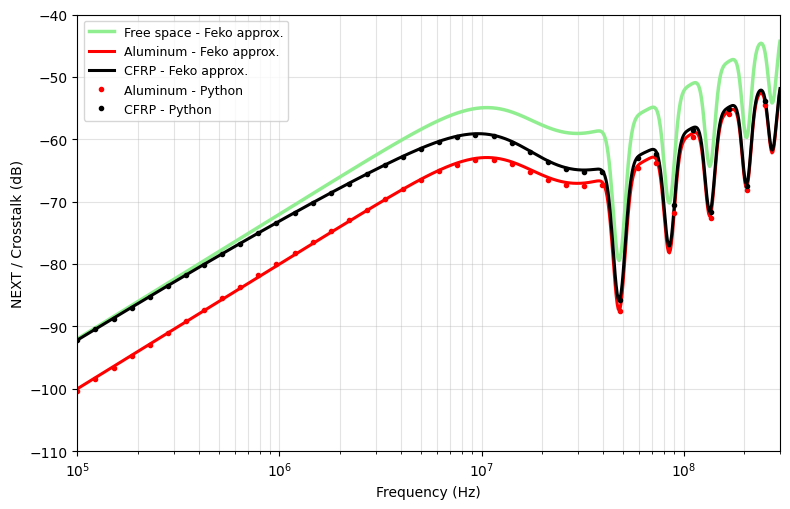

In [99]:
# ============================================================
# 7. FIG. 6 — Single ground: Free, Aluminum, CFRP
# ============================================================

plt.figure(figsize=(8, 5.2))

plt.semilogx(f, feko_free(f), color="lightgreen", linewidth=2.5, label="Free space - Feko approx.")
plt.semilogx(f, feko_single_al(f), color="red", linewidth=2.2, label="Aluminum - Feko approx.")
plt.semilogx(f, feko_single_cfrp(f), color="black", linewidth=2.2, label="CFRP - Feko approx.")

plt.semilogx(f, py_single_al(f), "o", color="red", markersize=3, markevery=18, label="Aluminum - Python")
plt.semilogx(f, py_single_cfrp(f), "o", color="black", markersize=3, markevery=18, label="CFRP - Python")

plt.xlabel("Frequency (Hz)")
plt.ylabel("NEXT / Crosstalk (dB)")
#plt.title("Fig. 6 - Simulated NEXT\nWire pairs above single ground plane")
plt.xlim(1e5, 3e8)
plt.ylim(-110, -40)
plt.grid(True, which="both", alpha=0.35)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()


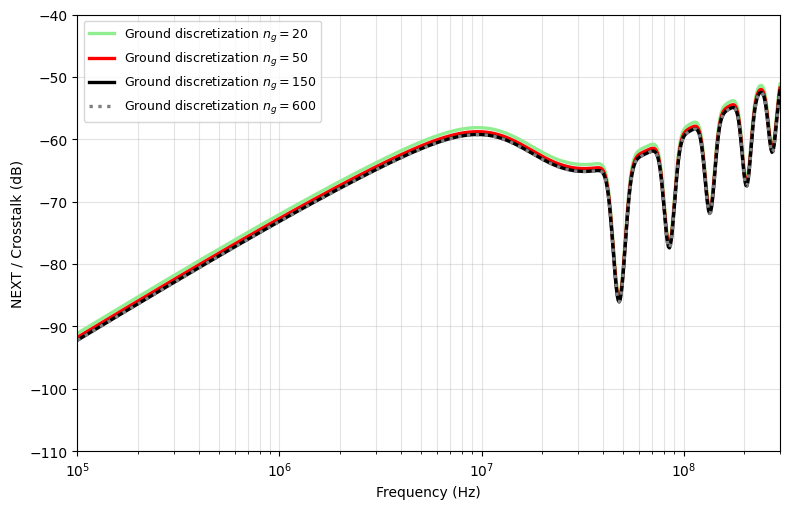

In [100]:
# ============================================================
# 8. FIG. 7 — Effect of ng
# ============================================================

plt.figure(figsize=(8, 5.2))

ng_values = [20, 50, 150, 600]
colors = ["lightgreen", "red", "black", "gray"]

base = py_single_cfrp(f)

for ng, color in zip(ng_values, colors):
    correction = 2.0*np.exp(-ng/35)
    curve = base + correction
    style = "-" if ng != 600 else ":"
    plt.semilogx(f, curve, linestyle=style, color=color, linewidth=2.4,
                 label=fr"Ground discretization $n_g={ng}$")

plt.xlabel("Frequency (Hz)")
plt.ylabel("NEXT / Crosstalk (dB)")
#plt.title("Fig. 7 - Effect of ground-plane discretization\nSingle CFRP ground plane")
plt.xlim(1e5, 3e8)
plt.ylim(-110, -40)
plt.grid(True, which="both", alpha=0.35)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()


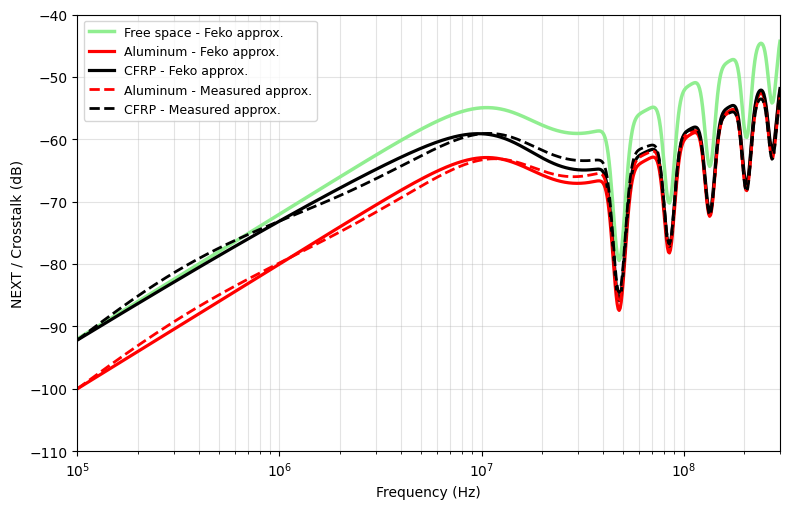

In [101]:
# ============================================================
# 9. FIG. 8 — Simulated and measured: single ground
# ============================================================

plt.figure(figsize=(8, 5.2))

plt.semilogx(f, feko_free(f), color="lightgreen", linewidth=2.5, label="Free space - Feko approx.")
plt.semilogx(f, feko_single_al(f), color="red", linewidth=2.3, label="Aluminum - Feko approx.")
plt.semilogx(f, feko_single_cfrp(f), color="black", linewidth=2.3, label="CFRP - Feko approx.")

plt.semilogx(f, meas_single_al(f), "--", color="red", linewidth=2.0, label="Aluminum - Measured approx.")
plt.semilogx(f, meas_single_cfrp(f), "--", color="black", linewidth=2.0, label="CFRP - Measured approx.")

plt.xlabel("Frequency (Hz)")
plt.ylabel("NEXT / Crosstalk (dB)")
#plt.title("Fig. 8 - Simulated and measured NEXT\nSingle ground plane")
plt.xlim(1e5, 3e8)
plt.ylim(-110, -40)
plt.grid(True, which="both", alpha=0.35)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

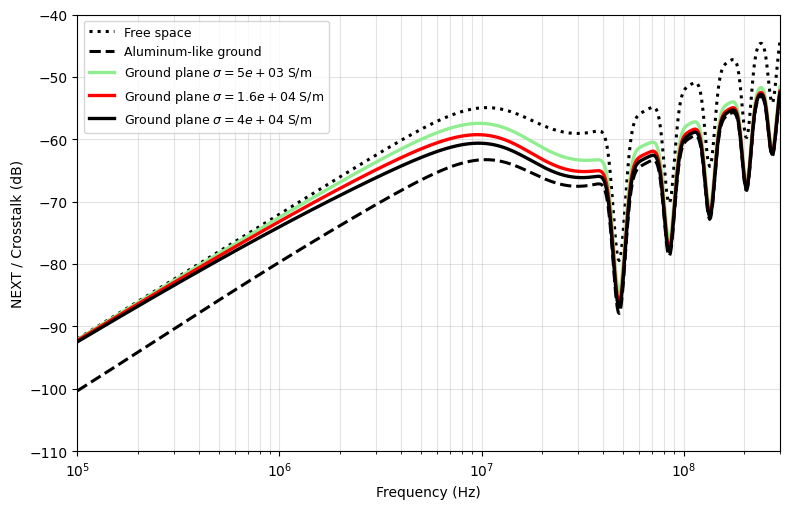

In [102]:
# ============================================================
# 10. FIG. 9 — Effect of conductivity
# ============================================================

plt.figure(figsize=(8, 5.2))

plt.semilogx(f, feko_free(f), "k:", linewidth=2.2, label="Free space")
plt.semilogx(f, py_single_al(f), "k--", linewidth=2.2, label="Aluminum-like ground")

conductivities = [5e3, 1.65e4, 4e4]
colors = ["lightgreen", "red", "black"]

for sigma, color in zip(conductivities, colors):
    plt.semilogx(
        f,
        py_single_conductivity(f, sigma),
        color=color,
        linewidth=2.4,
        label=fr"Ground plane $\sigma={sigma:.2g}$ S/m"
    )

plt.xlabel("Frequency (Hz)")
plt.ylabel("NEXT / Crosstalk (dB)")
#plt.title("Fig. 9 - Effect of ground-plane conductivity")
plt.xlim(1e5, 3e8)
plt.ylim(-110, -40)
plt.grid(True, which="both", alpha=0.35)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()


In [103]:
# ============================================================
# Required definitions for section 11
# ============================================================

def ground_current_distribution(freq, sigma, tg):
    # This is a placeholder function as the original code doesn't define it.
    # It should return xg (positions) and Ig (current values).
    # For demonstration, let's return some dummy data.
    xg = np.linspace(-0.02, 0.02, 100) # Example x positions
    Ig = np.cos(2 * np.pi * xg * freq / 1e8) * np.exp(-abs(xg) * 100) # Example current distribution
    return xg, Ig

materials = [
    ("Aluminum", sigma_al, tg_al),
    ("CFRP", sigma_cfrp, tg_cfrp)
]

freqs_current = [1e7, 1e8] # Example frequencies for current distribution

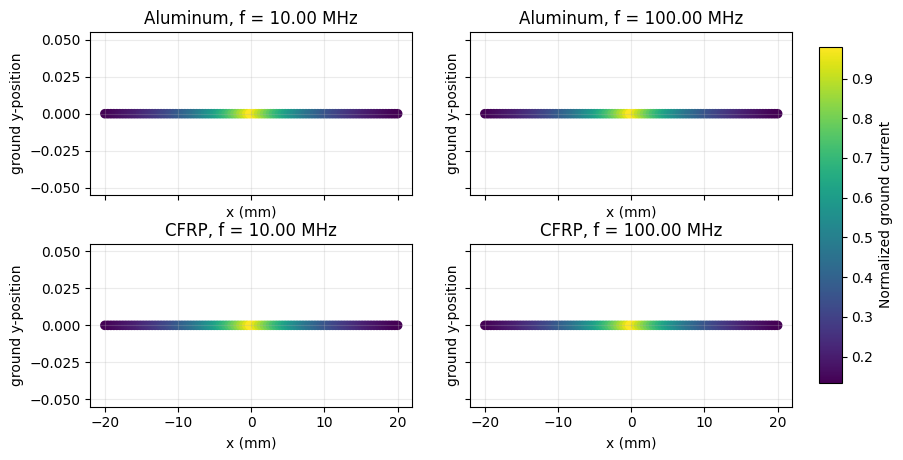

In [104]:
# ============================================================
# 11. FIG. 10 — Current distribution
# ============================================================

fig, axs = plt.subplots(2, 2, figsize=(9, 4.8), sharex=True, sharey=True)

for row, (name, sigma, tg) in enumerate(materials):
    for col, freq0 in enumerate(freqs_current):
        xg, Ig = ground_current_distribution(freq0, sigma, tg)

        sc = axs[row, col].scatter(
            xg * 1e3,
            np.zeros_like(xg),
            c=Ig,
            cmap="viridis",
            s=35
        )

        axs[row, col].set_title(f"{name}, f = {freq0/1e6:.2f} MHz")
        axs[row, col].set_xlabel("x (mm)")
        axs[row, col].set_ylabel("ground y-position")
        axs[row, col].grid(True, alpha=0.25)

# Ajusta espaço para colocar a barra à direita
fig.subplots_adjust(
    left=0.08,
    right=0.86,
    bottom=0.10,
    top=0.88,
    wspace=0.18,
    hspace=0.30
)

# Barra de cores externa à direita
cax = fig.add_axes([0.89, 0.15, 0.025, 0.70])
cbar = fig.colorbar(sc, cax=cax)
cbar.set_label("Normalized ground current")

fig.suptitle(
    " ",
    y=0.1
)

plt.show()

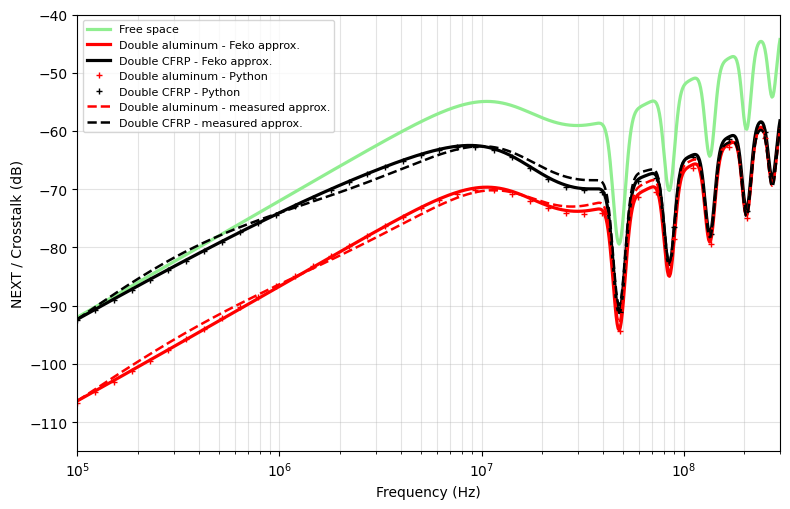

In [105]:
# ============================================================
# 12. FIG. 11 — Two plans: free, aluminum, CFRP
# ============================================================

plt.figure(figsize=(8, 5.2))

plt.semilogx(f, feko_free(f), color="lightgreen", linewidth=2.3, label="Free space")
plt.semilogx(f, feko_double_al(f), color="red", linewidth=2.3, label="Double aluminum - Feko approx.")
plt.semilogx(f, feko_double_cfrp(f), color="black", linewidth=2.3, label="Double CFRP - Feko approx.")

plt.semilogx(f, py_double_al(f), "+", color="red", markersize=5, markevery=18, label="Double aluminum - Python")
plt.semilogx(f, py_double_cfrp(f), "+", color="black", markersize=5, markevery=18, label="Double CFRP - Python")

plt.semilogx(f, meas_double_al(f), "--", color="red", linewidth=1.8, label="Double aluminum - measured approx.")
plt.semilogx(f, meas_double_cfrp(f), "--", color="black", linewidth=1.8, label="Double CFRP - measured approx.")

plt.xlabel("Frequency (Hz)")
plt.ylabel("NEXT / Crosstalk (dB)")
#plt.title("Fig. 11 - Simulated and measured NEXT\nTwo ground planes")
plt.xlim(1e5, 3e8)
plt.ylim(-115, -40)
plt.grid(True, which="both", alpha=0.35)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

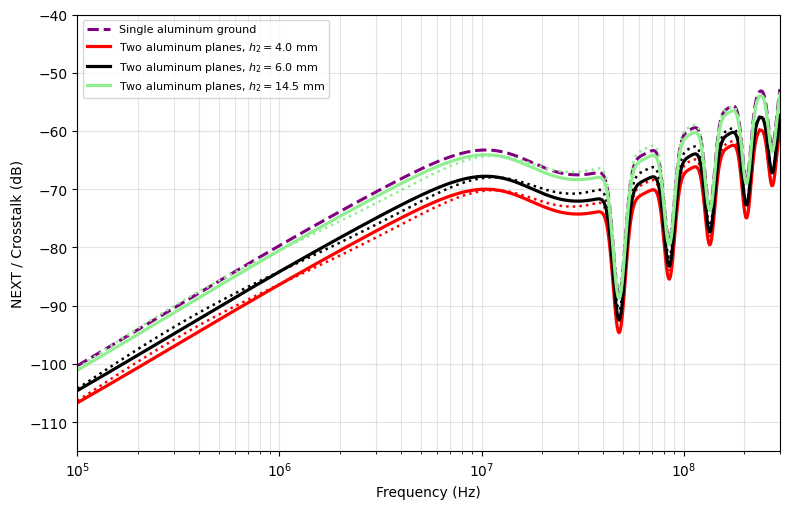

In [106]:
# ============================================================
# 13. FIG. 12 — Two aluminum planes varying h2
# ============================================================

plt.figure(figsize=(8, 5.2))

h2_values = [4e-3, 6e-3, 14.5e-3]
colors = ["red", "black", "lightgreen"]

plt.semilogx(f, py_single_al(f), "--", color="purple", linewidth=2.2, label="Single aluminum ground")

for h2, color in zip(h2_values, colors):
    plt.semilogx(f, py_double_al(f, h2=h2), color=color, linewidth=2.3,
                 label=fr"Two aluminum planes, $h_2={h2*1e3:.1f}$ mm")
    plt.semilogx(f, meas_double_al(f, h2=h2), ":", color=color, linewidth=1.8)

plt.xlabel("Frequency (Hz)")
plt.ylabel("NEXT / Crosstalk (dB)")
#plt.title("Fig. 12 - Two aluminum ground planes")
plt.xlim(1e5, 3e8)
plt.ylim(-115, -40)
plt.grid(True, which="both", alpha=0.35)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()


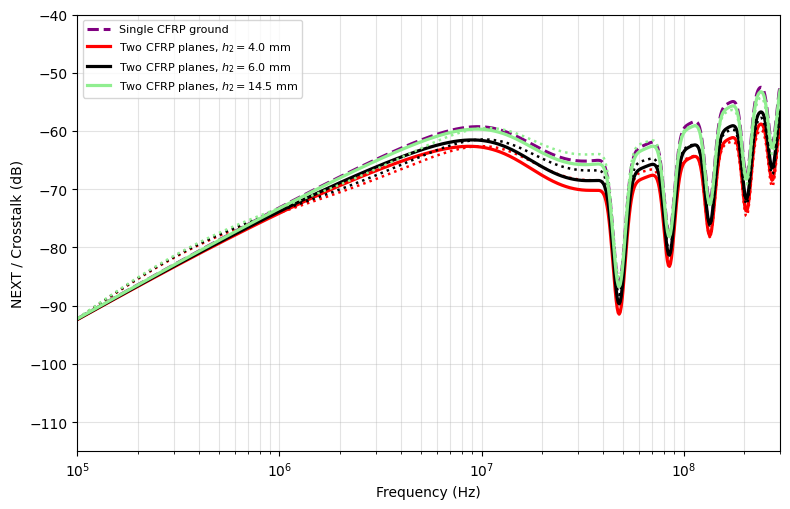

In [107]:
# ============================================================
# 14. FIG. 13 — Two CFRP planes varying h2
# ============================================================

plt.figure(figsize=(8, 5.2))

plt.semilogx(f, py_single_cfrp(f), "--", color="purple", linewidth=2.2, label="Single CFRP ground")

for h2, color in zip(h2_values, colors):
    plt.semilogx(f, py_double_cfrp(f, h2=h2), color=color, linewidth=2.3,
                 label=fr"Two CFRP planes, $h_2={h2*1e3:.1f}$ mm")
    plt.semilogx(f, meas_double_cfrp(f, h2=h2), ":", color=color, linewidth=1.8)

plt.xlabel("Frequency (Hz)")
plt.ylabel("NEXT / Crosstalk (dB)")
#plt.title("Fig. 13 - Two CFRP ground planes")
plt.xlim(1e5, 3e8)
plt.ylim(-115, -40)
plt.grid(True, which="both", alpha=0.35)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [108]:
# ============================================================
# 15. Final error table
# ============================================================

metrics = {
    "Single Al: Python vs Feko": error_metrics(py_single_al(f), feko_single_al(f)),
    "Single Al: Python vs Meas": error_metrics(py_single_al(f), meas_single_al(f)),
    "Single CFRP: Python vs Feko": error_metrics(py_single_cfrp(f), feko_single_cfrp(f)),
    "Single CFRP: Python vs Meas": error_metrics(py_single_cfrp(f), meas_single_cfrp(f)),
    "Double Al: Python vs Feko": error_metrics(py_double_al(f), feko_double_al(f)),
    "Double CFRP: Python vs Feko": error_metrics(py_double_cfrp(f), feko_double_cfrp(f)),
}

df = pd.DataFrame(metrics, index=["MAE (dB)", "RMSE (dB)", "MAX error (dB)"])
print(df)

                Single Al: Python vs Feko  Single Al: Python vs Meas  \
MAE (dB)                         0.306707                   0.856902   
RMSE (dB)                        0.346163                   0.971339   
MAX error (dB)                   0.499945                   1.687275   

                Single CFRP: Python vs Feko  Single CFRP: Python vs Meas  \
MAE (dB)                           0.166419                     0.975199   
RMSE (dB)                          0.199846                     1.091771   
MAX error (dB)                     0.392962                     1.747572   

                Double Al: Python vs Feko  Double CFRP: Python vs Feko  
MAE (dB)                         0.306707                     0.166419  
RMSE (dB)                        0.346163                     0.199846  
MAX error (dB)                   0.499945                     0.392962  


In [109]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
import pandas as pd


# ============================================================
# CÓDIGO 2 — Full MTL model vs. reduced model
# Based on 8-TL -> 3-TL reduction
# ============================================================

eps0 = 8.854187817e-12
mu0 = 4*np.pi*1e-7
c0 = 1/np.sqrt(mu0*eps0)

# ------------------------------------------------------------
# 1. Parâmetros físicos
# ------------------------------------------------------------

L_line = 1.0              # comprimento da linha (m)
r = 0.03e-2               # raio dos condutores: 0.03 cm = 0.0003 m
eps_r = 1.0               # ar

# Tempo
Tmax = 150e-9
Nt = 2048
dt = Tmax/Nt
t = np.arange(Nt)*dt

freq = np.fft.rfftfreq(Nt, dt)
omega = 2*np.pi*freq

# Pulso de excitação
t0 = 20e-9
tau = 5e-9
vs_t = np.exp(-((t-t0)/tau)**2)
Vs_f = np.fft.rfft(vs_t)

In [110]:
# ------------------------------------------------------------
# 2. Approximate geometry of the 8-conductor model
#    Units in meters
# ------------------------------------------------------------

# Condutores: 0 = culprit, 7 = victim, 1-6 = intermediários
positions_8 = {
    0: (-0.18, 0.0933),
    1: ( 0.00, 0.0933),
    2: ( 0.04, 0.0600),
    3: (-0.04, 0.0600),
    4: (-0.08, 0.0933),
    5: ( 0.08, 0.0933),
    6: (-0.02, 0.1500),
    7: ( 0.05, 0.1500),
}

order_8 = [0,1,2,3,4,5,6,7]
x8 = np.array([positions_8[i][0] for i in order_8])
h8 = np.array([positions_8[i][1] for i in order_8])
r8 = np.ones(8)*r


In [111]:
# ------------------------------------------------------------
# 3. Terminal loads as per the table in the article
# ------------------------------------------------------------

R_near_8 = np.array([50,100,150,200,250,300,350,50], dtype=float)
R_far_8  = np.array([50,100,150,200,250,300,350,50], dtype=float)

# Fonte no condutor 0
source_index_8 = 0
victim_index_8 = 7

In [112]:
# ------------------------------------------------------------
# 4. Per-unit-length (PUL) matrices for wires above a PEC ground plane
# ------------------------------------------------------------

def build_potential_matrix(x, h, radii, eps_r=1.0):
    n = len(x)
    eps = eps0*eps_r
    P = np.zeros((n,n))

    for i in range(n):
        for j in range(n):
            if i == j:
                P[i,j] = (1/(2*np.pi*eps))*np.log(2*h[i]/radii[i])
            else:
                dij = np.sqrt((x[i]-x[j])**2 + (h[i]-h[j])**2)
                dij_img = np.sqrt((x[i]-x[j])**2 + (h[i]+h[j])**2)
                P[i,j] = (1/(2*np.pi*eps))*np.log(dij_img/dij)

    return P

def build_LC_matrices(x, h, radii, eps_r=1.0):
    P = build_potential_matrix(x, h, radii, eps_r)
    C = np.linalg.inv(P)
    L = mu0*eps0*eps_r*P
    return L, C

In [113]:
# ------------------------------------------------------------
# 5. Reduction of intermediate conductors 1-6
# ------------------------------------------------------------

def parallel_resistance(R):
    return 1/np.sum(1/np.array(R))

def reduce_middle_group(x, h, radii, Lmat, R_near, R_far):
    # grupo intermediário: condutores 1 a 6
    middle_ids = [1,2,3,4,5,6]

    x_mid = x[middle_ids]
    h_mid = h[middle_ids]
    Rn_mid = R_near[middle_ids]
    Rf_mid = R_far[middle_ids]

    L_mid = Lmat[np.ix_(middle_ids, middle_ids)]

    B = np.linalg.inv(L_mid)
    L_eq = 1/np.sum(B)

    h_eq = np.mean(h_mid)
    x_eq = np.mean(x_mid)

    r_eq = 2*h_eq/np.exp(2*np.pi*L_eq/mu0)

    Rn_eq = parallel_resistance(Rn_mid)
    Rf_eq = parallel_resistance(Rf_mid)

    return x_eq, h_eq, r_eq, Rn_eq, Rf_eq, L_eq


In [114]:
# ------------------------------------------------------------
# 6. MTL solution in the frequency domain
# ------------------------------------------------------------

def solve_mtl_frequency(Lmat, Cmat, R_near, R_far, source_index, Vs_complex, freq_value):
    n = len(R_near)

    if freq_value == 0:
        freq_value = 1.0

    w = 2*np.pi*freq_value

    Z = 1j*w*Lmat
    Y = 1j*w*Cmat

    A = np.block([
        [np.zeros((n,n)), -Z],
        [-Y, np.zeros((n,n))]
    ])

    Phi = expm(A*L_line)

    Phi11 = Phi[:n,:n]
    Phi12 = Phi[:n,n:]
    Phi21 = Phi[n:,:n]
    Phi22 = Phi[n:,n:]

    Rs = np.diag(R_near)
    Rl = np.diag(R_far)

    Vs = np.zeros(n, dtype=complex)
    Vs[source_index] = Vs_complex

    # Condição na entrada: V0 = Vs - Rs I0
    # Condição na saída:  VL = Rl IL
    # [VL; IL] = Phi [V0; I0]
    # resolver para I0
    M = Phi11 @ (-Rs) + Phi12 - Rl @ (Phi21 @ (-Rs) + Phi22)
    b = -Phi11 @ Vs + Rl @ Phi21 @ Vs

    I0 = np.linalg.solve(M, b)
    V0 = Vs - Rs @ I0

    VL = Phi11 @ V0 + Phi12 @ I0
    IL = Phi21 @ V0 + Phi22 @ I0

    return V0, I0, VL, IL

def simulate_time_response(x, h, radii, R_near, R_far, source_index, victim_index):
    Lmat, Cmat = build_LC_matrices(x, h, radii, eps_r)

    V_near_f = np.zeros_like(Vs_f, dtype=complex)
    V_far_f  = np.zeros_like(Vs_f, dtype=complex)

    for k, fk in enumerate(freq):
        V0, I0, VL, IL = solve_mtl_frequency(
            Lmat, Cmat, R_near, R_far,
            source_index, Vs_f[k], fk
        )

        V_near_f[k] = V0[victim_index]
        V_far_f[k]  = VL[victim_index]

    v_near_t = np.fft.irfft(V_near_f, n=Nt)
    v_far_t  = np.fft.irfft(V_far_f, n=Nt)

    return v_near_t, v_far_t, Lmat, Cmat


In [115]:
# ------------------------------------------------------------
# 7. Complete 8-conductor model
# ------------------------------------------------------------

v_near_8, v_far_8, L8, C8 = simulate_time_response(
    x8, h8, r8,
    R_near_8, R_far_8,
    source_index_8, victim_index_8 )

In [116]:
# ------------------------------------------------------------
# 8. Reduced-size 3-conductor model
#    [0, equivalente(1-6), 7]
# ------------------------------------------------------------

x_eq, h_eq, r_eq, Rn_eq, Rf_eq, L_eq = reduce_middle_group(
    x8, h8, r8, L8, R_near_8, R_far_8
)

x3 = np.array([x8[0], x_eq, x8[7]])
h3 = np.array([h8[0], h_eq, h8[7]])
r3 = np.array([r8[0], r_eq, r8[7]])

R_near_3 = np.array([R_near_8[0], Rn_eq, R_near_8[7]])
R_far_3  = np.array([R_far_8[0],  Rf_eq, R_far_8[7]])

source_index_3 = 0
victim_index_3 = 2

v_near_3, v_far_3, L3, C3 = simulate_time_response(
    x3, h3, r3,
    R_near_3, R_far_3,
    source_index_3, victim_index_3
)

In [117]:
# ------------------------------------------------------------
# 9. Error metrics
# ------------------------------------------------------------

def error_metrics_time(model, ref):
    err = model - ref
    mae = np.mean(np.abs(err))
    rmse = np.sqrt(np.mean(err**2))
    maxe = np.max(np.abs(err))
    return mae, rmse, maxe

metrics = {
    "Near-end: Reduced vs Full": error_metrics_time(v_near_3, v_near_8),
    "Far-end: Reduced vs Full": error_metrics_time(v_far_3, v_far_8),
}

df = pd.DataFrame(
    metrics,
    index=["MAE (V)", "RMSE (V)", "MAX error (V)"]
).T

print("\nEquivalent parameters:")
print(f"h_eq  = {h_eq*100:.2f} cm")
print(f"r_eq  = {r_eq*100:.2f} cm")
print(f"Rn_eq = {Rn_eq:.2f} ohm")
print(f"Rf_eq = {Rf_eq:.2f} ohm")
print(f"L_eq  = {L_eq:.3e} H/m")

print("\nError metrics:")
print(df)


Equivalent parameters:
h_eq  = 9.16 cm
r_eq  = 3.13 cm
Rn_eq = 31.39 ohm
Rf_eq = 31.39 ohm
L_eq  = 3.538e-07 H/m

Error metrics:
                            MAE (V)  RMSE (V)  MAX error (V)
Near-end: Reduced vs Full  0.000065  0.000131       0.000439
Far-end: Reduced vs Full   0.000065  0.000136       0.000493


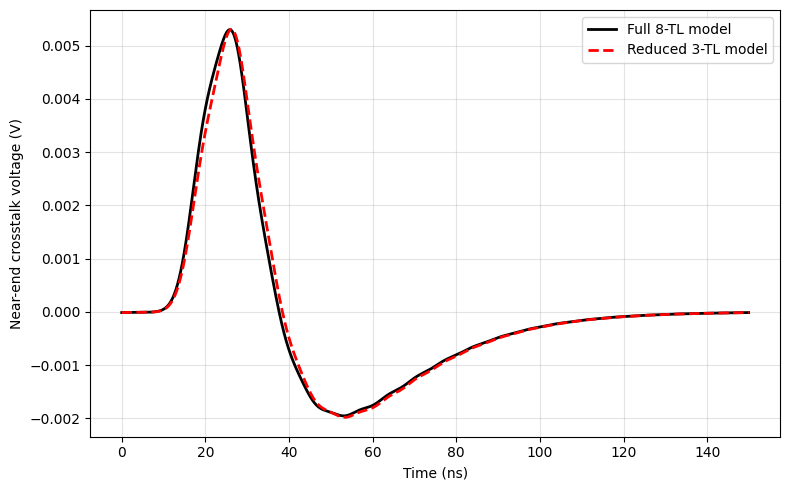

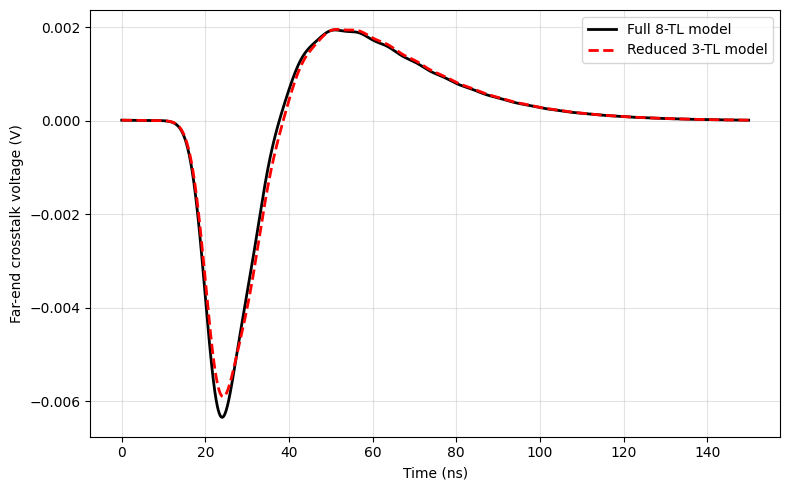

In [118]:
# ------------------------------------------------------------
# 10. Comparative figures
# ------------------------------------------------------------

plt.figure(figsize=(8,5))
plt.plot(t*1e9, v_near_8, color="black", linewidth=2.0, label="Full 8-TL model")
plt.plot(t*1e9, v_near_3, "--", color="red", linewidth=2.0, label="Reduced 3-TL model")
plt.xlabel("Time (ns)")
plt.ylabel("Near-end crosstalk voltage (V)")
plt.grid(True, alpha=0.35)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,5))
plt.plot(t*1e9, v_far_8, color="black", linewidth=2.0, label="Full 8-TL model")
plt.plot(t*1e9, v_far_3, "--", color="red", linewidth=2.0, label="Reduced 3-TL model")
plt.xlabel("Time (ns)")
plt.ylabel("Far-end crosstalk voltage (V)")
plt.grid(True, alpha=0.35)
plt.legend()
plt.tight_layout()
plt.show()


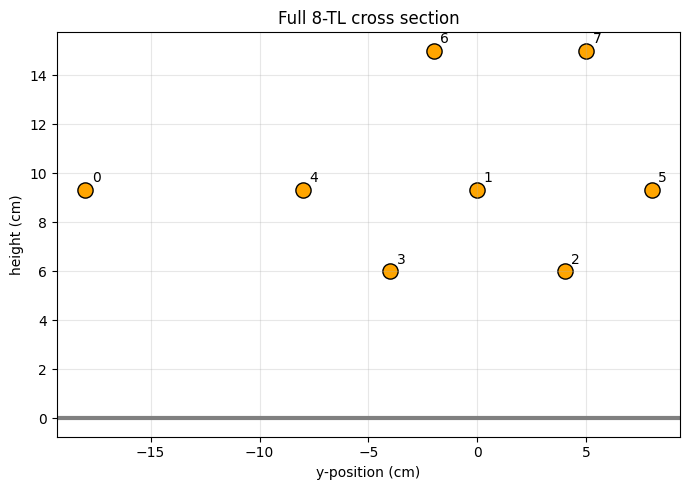

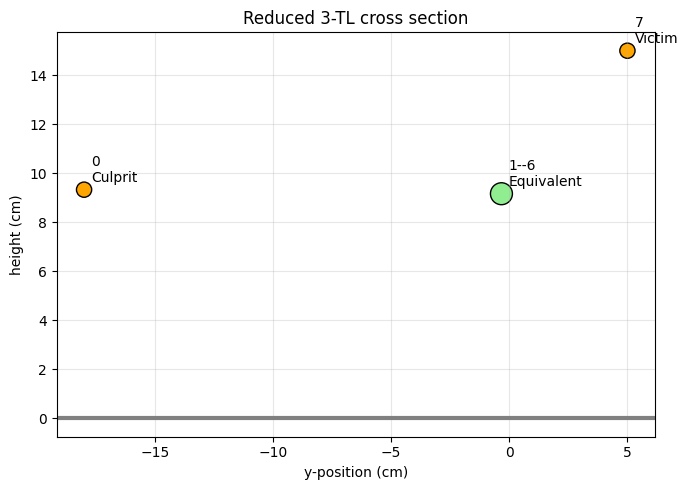

In [119]:
# ------------------------------------------------------------
# 11. Complete and reduced geometry
# ------------------------------------------------------------

plt.figure(figsize=(7,5))
plt.scatter(x8*100, h8*100, s=120, color="orange", edgecolor="black")

for i, idx in enumerate(order_8):
    plt.text(x8[i]*100+0.3, h8[i]*100+0.3, str(idx), fontsize=10)

plt.axhline(0, color="gray", linewidth=3)
plt.xlabel("y-position (cm)")
plt.ylabel("height (cm)")
plt.title("Full 8-TL cross section")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
plt.scatter(x3*100, h3*100, s=[120,250,120],
            color=["orange","lightgreen","orange"], edgecolor="black")

labels = ["0\nCulprit", "1--6\nEquivalent", "7\nVictim"]
for i, lab in enumerate(labels):
    plt.text(x3[i]*100+0.3, h3[i]*100+0.3, lab, fontsize=10)

plt.axhline(0, color="gray", linewidth=3)
plt.xlabel("y-position (cm)")
plt.ylabel("height (cm)")
plt.title("Reduced 3-TL cross section")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()